In [50]:
import pandas as pd


In [9]:
departments = pd.read_csv('/Users/angieshen/Desktop/DataFest2026/departments.csv')
diagnosis = pd.read_csv('/Users/angieshen/Desktop/DataFest2026/diagnosis.csv')
encounters = pd.read_csv('/Users/angieshen/Desktop/DataFest2026/encounters.csv')
patients = pd.read_csv('/Users/angieshen/Desktop/DataFest2026/patients.csv')
social_determinants = pd.read_csv('/Users/angieshen/Desktop/DataFest2026/social_determinants.csv')
tigercensuscodes = pd.read_csv('/Users/angieshen/Desktop/DataFest2026/tigercensuscodes.csv')

/var/folders/qt/47k9y_w17z991s1knvcgn4fm0000gn/T/ipykernel_49874/137842035.py:5: DtypeWarning: Columns (0: Domain) have mixed types. Specify dtype option on import or set low_memory=False.
  social_determinants = pd.read_csv('/Users/angieshen/Desktop/DataFest2026/social_determinants.csv')


In [11]:
encounters.head()

,Date,AdmissionInstant,AdmitYear,AdmitMonth,AdmitDay,AdmitHour,AdmitMinute,AdmissionSource,AdmissionType,DischargeInstant,...,AttendingProviderDurableKey,DischargeProviderDurableKey,DepartmentKey,PrimaryDiagnosisKey,IsEdVisit,IsHospitalAdmission,IsHospitalOutpatientVisit,IsInpatientAdmission,IsObservation,IsOutpatientFaceToFaceVisit
0,04/25/22,2022-04-25 20:33:00,2022.0,4.0,25.0,20.0,33.0,Non-Health Care Facility Point of Origin,Elective,2022-04-25 21:35:00,...,2982,2982,27,910699,0,1,0,0,1,0
1,04/29/22,2022-04-29 18:18:00,2022.0,4.0,29.0,18.0,18.0,Clinic/Physician Referral,Elective,2022-04-29 18:20:00,...,2979,2979,27,-1,0,1,0,0,1,0
2,01/10/22,2022-01-10 05:52:00,2022.0,1.0,10.0,5.0,52.0,Non-Health Care Facility Point of Origin,Elective,2022-01-12 11:43:00,...,6223,7015,27,468738,0,1,0,1,0,0
3,03/08/22,2022-03-08 09:08:00,2022.0,3.0,8.0,9.0,8.0,Non-Health Care Facility Point of Origin,Elective,2022-03-10 13:45:00,...,7973,7973,27,468492,0,1,0,1,0,0
4,03/16/22,2022-03-16 14:19:00,2022.0,3.0,16.0,14.0,19.0,Non-Health Care Facility Point of Origin,Elective,2022-03-16 16:00:00,...,6223,2982,27,907210,0,1,0,0,1,0


In [16]:
patients.head()

,CensusBlockGroupFipsCode,DurableKey,FirstRace,MaritalStatus,MyChartStatus,OmbEthnicity,OmbRace,SexAssignedAtBirth,SexualOrientation,SmokingStatus,VitalStatus,PatientBirthYearBin
0,201770007002,5.0,White or Caucasian,Single,Activated,Not Hispanic or Latino,White,*Unspecified,*Unspecified,Never,Alive,1970.0
1,*Unspecified,8.0,White or Caucasian,*Unspecified,Inactivated,Unknown,White,*Unspecified,*Unspecified,*Unknown,Alive,1980.0
2,*Unspecified,9.0,"Hispanic, Latino, or Spanish",Married,*Unspecified,Unknown,Some Other Race,*Unspecified,*Unspecified,Never,Alive,1955.0
3,*Unspecified,11.0,"Hispanic, Latino, or Spanish",Unknown,*Unspecified,Hispanic or Latino,Some Other Race,*Unspecified,*Unspecified,Never,Alive,1970.0
4,*Unspecified,12.0,Black or African American,Single,*Unspecified,Not Hispanic or Latino,Black or African American,*Unspecified,*Unspecified,Never,Alive,1980.0


In [17]:
diagnosis.head()

,DiagnosisKey,GroupName,GroupCode,DiagnosisName,DiagnosisValue
0,2.0,Typhoid and paratyphoid fevers,ICD-10-CM: A01,"Paratyphoid fever, unspecified( ICD-10-CM: A01...",A01.4
1,3.0,Respiratory tuberculosis,ICD-10-CM: A15,Primary respiratory tuberculosis( ICD-10-CM: A...,A15.7
2,7.0,Fracture at wrist and hand level,ICD-10-CM: S62,"Displaced fracture of pisiform, unspecified wr...",S62.163K
3,8.0,Fracture of rib,ICD-10-CM: S22,"Multiple fractures of ribs, right side, subseq...",S22.41XG
4,9.0,Fracture at wrist and hand level,ICD-10-CM: S62,Nondisplaced fracture of distal phalanx of lef...,S62.663G


In [18]:
social_determinants.head()

,DisplayName,AnswerText,EncounterKey,PatientDurableKey,Domain
0,*Unspecified,Unknown,147506236.0,5.0,NaN
1,*Unspecified,Never,154008498.0,6094715.0,NaN
2,*Unspecified,Never,152425953.0,6094715.0,NaN
3,*Unspecified,Past,153702939.0,5.0,NaN
4,*Unspecified,Past,152713763.0,5.0,NaN


In [19]:
diagnosis.info()

<class 'pandas.DataFrame'>
RangeIndex: 1531262 entries, 0 to 1531261
Data columns (total 5 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   DiagnosisKey    1531262 non-null  float64
 1   GroupName       1531262 non-null  str    
 2   GroupCode       1531262 non-null  str    
 3   DiagnosisName   1531262 non-null  str    
 4   DiagnosisValue  1531262 non-null  str    
dtypes: float64(1), str(4)
memory usage: 58.4 MB


In [21]:
diag = diagnosis.dropna()

In [24]:
enc = encounters.dropna()

In [26]:
pat = patients.dropna()

In [ ]:
soc = social_determinants.dropna()

In [226]:
# Expanded Mapping for Patient Journey Analysis
# Categories: Chronic, Acute, or Other (Preventative/Symptoms)

dx_map = {
    # --- CHRONIC (Long-term management) ---
    'E11': 'Chronic',  # Type 2 Diabetes
    'E10': 'Chronic',  # Type 1 Diabetes
    'I10': 'Chronic',  # Essential Hypertension
    'I11': 'Chronic',  # Hypertensive Heart Disease
    'I25': 'Chronic',  # Ischemic Heart Disease
    'J44': 'Chronic',  # COPD
    'J45': 'Chronic',  # Asthma
    'F32': 'Chronic',  # Depressive Episodes
    'F41': 'Chronic',  # Anxiety Disorders
    'N18': 'Chronic',  # Chronic Kidney Disease
    'M17': 'Chronic',  # Osteoarthritis of Knee
    
    # --- ACUTE (Sudden onset / Injury) ---
    'J06': 'Acute',    # Acute Upper Respiratory Infection (Cold)
    'J11': 'Acute',    # Influenza
    'J18': 'Acute',    # Pneumonia
    'S82': 'Acute',    # Fracture of Lower Leg
    'S62': 'Acute',    # Fracture at Wrist/Hand level
    'K35': 'Acute',    # Acute Appendicitis
    'A09': 'Acute',    # Infectious Gastroenteritis (Stomach flu)
    'N39': 'Acute',    # Urinary Tract Infection (UTI)
    'I21': 'Acute',    # Acute Myocardial Infarction (Heart Attack)
    'R50': 'Acute',    # Fever (unspecified)
    
    # --- OTHER (Preventative / Diagnostic / Symptoms) ---
    'Z00': 'Other',    # General Adult Medical Exam
    'Z01': 'Other',    # Other Special Exams (e.g., vision/hearing)
    'Z12': 'Other',    # Screening for Malignant Neoplasm (Cancer screening)
    'Z23': 'Other',    # Encounter for Immunizations
    'R05': 'Other',    # Cough
    'R07': 'Other',    # Pain in Throat/Chest
    'R11': 'Other'     # Nausea and Vomiting
}

# --- Application Logic ---
# Extracting the 3-digit prefix and applying the map
diag['dx_prefix'] = diag['GroupCode'].str.strip().str[:3].str.upper()
diag['journeyType'] = diag['dx_prefix'].map(dx_map).fillna('Other/Unclassified')

In [ ]:
diag.head()
diag.drop(columns=['journey_type'])

,DiagnosisKey,GroupName,GroupCode,DiagnosisName,DiagnosisValue,dx_prefix,journeyType
0,2.0,Typhoid and paratyphoid fevers,ICD-10-CM: A01,"Paratyphoid fever, unspecified( ICD-10-CM: A01...",A01.4,ICD,Other/Unclassified
1,3.0,Respiratory tuberculosis,ICD-10-CM: A15,Primary respiratory tuberculosis( ICD-10-CM: A...,A15.7,ICD,Other/Unclassified
2,7.0,Fracture at wrist and hand level,ICD-10-CM: S62,"Displaced fracture of pisiform, unspecified wr...",S62.163K,ICD,Other/Unclassified
3,8.0,Fracture of rib,ICD-10-CM: S22,"Multiple fractures of ribs, right side, subseq...",S22.41XG,ICD,Other/Unclassified
4,9.0,Fracture at wrist and hand level,ICD-10-CM: S62,Nondisplaced fracture of distal phalanx of lef...,S62.663G,ICD,Other/Unclassified
...,...,...,...,...,...,...,...
1531257,1629328.0,Reserved for inherently not codable concepts w...,ICD-10-CM: IMO0001,Reserved for inherently not codable concepts w...,IMO0001,ICD,Other/Unclassified
1531258,1629331.0,Reserved for concepts with insufficient inform...,ICD-10-CM: IMO0002,Reserved for concepts with insufficient inform...,IMO0002,ICD,Other/Unclassified
1531259,1629340.0,Reserved for concepts with insufficient inform...,ICD-10-CM: IMO0002,Reserved for concepts with insufficient inform...,IMO0002,ICD,Other/Unclassified
1531260,1629341.0,Reserved for concepts with insufficient inform...,ICD-10-CM: IMO0002,Reserved for concepts with insufficient inform...,IMO0002,ICD,Other/Unclassified


In [40]:
unclassified = diag[diag['journeyType'] == 'Other/Unclassified']
print(unclassified['GroupCode'].value_counts().head(20))

GroupCode
ICD-10-CM: S82        84079
ICD-10-CM: S52        68275
ICD-10-CM: S62        58559
ICD-10-CM: S72        57718
ICD-10-CM: S06        50269
ICD-10-CM: S42        45886
ICD-10-CM: S92        39515
ICD-10-CM: IMO0001    28789
ICD-10-CM: S32        20330
ICD-10-CM: S02        17259
ICD-10-CM: S22        16511
ICD-10-CM: IMO0002    14505
ICD-10-CM: S01        12345
ICD-10-CM: T23        12055
ICD-10-CM: S99        11765
ICD-10-CM: M84        11062
ICD-10-CM: O36        10691
ICD-10-CM: S61        10501
ICD-10-CM: L08        10446
ICD-10-CM: S63         9535
Name: count, dtype: int64


In [41]:
# Mapping based on your frequency distribution
specific_dx_map = {
    # --- ACUTE: Fractures and Head Injuries (The "S" Group) ---
    'S82': 'Acute',  # Fracture of lower leg (Your #1 code!)
    'S52': 'Acute',  # Fracture of forearm
    'S62': 'Acute',  # Fracture at wrist/hand
    'S72': 'Acute',  # Fracture of femur (hip/thigh)
    'S06': 'Acute',  # Intracranial injury (Concussion/TBI)
    'S42': 'Acute',  # Fracture of shoulder/upper arm
    'S92': 'Acute',  # Fracture of foot
    'S32': 'Acute',  # Fracture of lumbar spine/pelvis
    'S02': 'Acute',  # Fracture of skull/facial bones
    'S22': 'Acute',  # Fracture of ribs/thoracic spine
    'S01': 'Acute',  # Open wound of head
    'S99': 'Acute',  # Other injuries of foot
    'S61': 'Acute',  # Open wound of wrist/hand
    'S63': 'Acute',  # Dislocation/sprain at wrist/hand
    'T23': 'Acute',  # Burns of wrist and hand
    
    # --- CHRONIC / SEMI-CHRONIC ---
    'M84': 'Chronic', # Disorder of continuity of bone (Stress fractures/Non-union)
    'L08': 'Chronic', # Other local infections of skin (can be recurring)
    
    # --- SPECIAL JOURNEYS ---
    'O36': 'Other',   # Maternal care for other fetal problems (Pregnancy)
    
    # --- SYSTEM CODES ---
    'IMO': 'Other'    # Interface Terminology (Usually custom hospital search terms)
}

# Apply to your dataframe
# We use .str.extract to pull the alphabetic prefix and the first two numbers
diag['dx_clean'] = diag['GroupCode'].str.extract(r'([A-Z]\d{2})')
diag['journeyType'] = diag['dx_clean'].map(specific_dx_map).fillna('Other/Unclassified')

In [42]:
diag.head()

,DiagnosisKey,GroupName,GroupCode,DiagnosisName,DiagnosisValue,dx_prefix,journey_type,journeyType,dx_clean
0,2.0,Typhoid and paratyphoid fevers,ICD-10-CM: A01,"Paratyphoid fever, unspecified( ICD-10-CM: A01...",A01.4,ICD,Other/Unclassified,Other/Unclassified,A01
1,3.0,Respiratory tuberculosis,ICD-10-CM: A15,Primary respiratory tuberculosis( ICD-10-CM: A...,A15.7,ICD,Other/Unclassified,Other/Unclassified,A15
2,7.0,Fracture at wrist and hand level,ICD-10-CM: S62,"Displaced fracture of pisiform, unspecified wr...",S62.163K,ICD,Other/Unclassified,Acute,S62
3,8.0,Fracture of rib,ICD-10-CM: S22,"Multiple fractures of ribs, right side, subseq...",S22.41XG,ICD,Other/Unclassified,Acute,S22
4,9.0,Fracture at wrist and hand level,ICD-10-CM: S62,Nondisplaced fracture of distal phalanx of lef...,S62.663G,ICD,Other/Unclassified,Acute,S62


In [38]:
departments.head()

,DepartmentKey,Address,City,County,DepartmentName,DepartmentSpecialty,DepartmentType,PostalCode,CensusTract
0,-3,*Deleted,*Deleted,*Deleted,*Deleted,*Deleted,*Deleted,*Deleted,NaN
1,-2,*Not Applicable,*Not Applicable,*Not Applicable,*Not Applicable,*Not Applicable,*Not Applicable,*Not Applicable,NaN
2,-1,*Unspecified,*Unspecified,*Unspecified,*Unspecified,*Unspecified,*Unspecified,*Unspecified,NaN
3,1,1500 SW 10th ST,TOPEKA,*Unspecified,INITIAL DEPT,*Unspecified,*Unknown,66604,2.017700e+10
4,2,1979 Milky Way,VERONA,*Unspecified,EHS UM DEPT,*Unspecified,*Unknown,53593,5.502501e+10


In [55]:
pd.set_option('display.max_rows', None)
diag['GroupCode'].value_counts()

GroupCode
ICD-10-CM: S82            84079
ICD-10-CM: S52            68275
ICD-10-CM: S62            58559
ICD-10-CM: S72            57718
ICD-10-CM: S06            50269
ICD-10-CM: S42            45886
ICD-10-CM: S92            39515
ICD-10-CM: IMO0001        28789
ICD-10-CM: S32            20330
ICD-10-CM: S02            17259
ICD-10-CM: S22            16511
ICD-10-CM: IMO0002        14505
ICD-10-CM: S01            12345
ICD-10-CM: T23            12055
ICD-10-CM: S99            11765
ICD-10-CM: M84            11062
ICD-10-CM: O36            10691
ICD-10-CM: S61            10501
ICD-10-CM: L08            10446
ICD-10-CM: S63             9535
ICD-10-CM: L97             8657
ICD-10-CM: T50             8073
ICD-10-CM: E11             8040
ICD-10-CM: Z15             7598
ICD-10-CM: S12             7509
ICD-10-CM: T45             7329
ICD-10-CM: T22             7263
ICD-10-CM: W57             7177
ICD-10-CM: S89             6871
ICD-10-CM: S91             6782
ICD-10-CM: S60             676

In [71]:
del diag['journey_type']


In [72]:
diag.head()

,DiagnosisKey,GroupName,GroupCode,DiagnosisName,DiagnosisValue,dx_prefix,journeyType,dx_clean
0,2.0,Typhoid and paratyphoid fevers,ICD-10-CM: A01,"Paratyphoid fever, unspecified( ICD-10-CM: A01...",A01.4,ICD,Other/Unclassified,A01
1,3.0,Respiratory tuberculosis,ICD-10-CM: A15,Primary respiratory tuberculosis( ICD-10-CM: A...,A15.7,ICD,Other/Unclassified,A15
2,7.0,Fracture at wrist and hand level,ICD-10-CM: S62,"Displaced fracture of pisiform, unspecified wr...",S62.163K,ICD,Acute,S62
3,8.0,Fracture of rib,ICD-10-CM: S22,"Multiple fractures of ribs, right side, subseq...",S22.41XG,ICD,Acute,S22
4,9.0,Fracture at wrist and hand level,ICD-10-CM: S62,Nondisplaced fracture of distal phalanx of lef...,S62.663G,ICD,Acute,S62


In [73]:
del diag['journeyType']
del diag['dx_prefix']

In [74]:
diag.head()

,DiagnosisKey,GroupName,GroupCode,DiagnosisName,DiagnosisValue,dx_clean
0,2.0,Typhoid and paratyphoid fevers,ICD-10-CM: A01,"Paratyphoid fever, unspecified( ICD-10-CM: A01...",A01.4,A01
1,3.0,Respiratory tuberculosis,ICD-10-CM: A15,Primary respiratory tuberculosis( ICD-10-CM: A...,A15.7,A15
2,7.0,Fracture at wrist and hand level,ICD-10-CM: S62,"Displaced fracture of pisiform, unspecified wr...",S62.163K,S62
3,8.0,Fracture of rib,ICD-10-CM: S22,"Multiple fractures of ribs, right side, subseq...",S22.41XG,S22
4,9.0,Fracture at wrist and hand level,ICD-10-CM: S62,Nondisplaced fracture of distal phalanx of lef...,S62.663G,S62


In [75]:
len(diag.loc[diag['GroupCode'] == 'ICD-10-CM: F03'])

564

In [63]:
len(diag.loc[diag['GroupCode'] == 'ICD-10-CM: F01'])

349

In [64]:
len(diag.loc[diag['GroupCode'] == 'ICD-10-CM: F02'])

1587

In [76]:
diag.loc[diag['GroupCode'] == 'ICD-10-CM: F02'].head()

,DiagnosisKey,GroupName,GroupCode,DiagnosisName,DiagnosisValue,dx_clean
7930,7612.0,Dementia in other diseases classified elsewhere,ICD-10-CM: F02,Dementia in other diseases classified elsewher...,F02.818,F02
26091,24910.0,Dementia in other diseases classified elsewhere,ICD-10-CM: F02,Dementia in other diseases classified elsewher...,F02.A0,F02
26150,24962.0,Dementia in other diseases classified elsewhere,ICD-10-CM: F02,Dementia in other diseases classified elsewher...,F02.A0,F02
26152,24963.0,Dementia in other diseases classified elsewhere,ICD-10-CM: F02,Dementia in other diseases classified elsewher...,F02.C0,F02
26215,25008.0,Dementia in other diseases classified elsewhere,ICD-10-CM: F02,Dementia in other diseases classified elsewher...,F02.A18,F02


In [65]:
len(diag.loc[diag['GroupCode'] == 'ICD-10-CM: G30'])

462

In [77]:
enc.head()

,Date,AdmissionInstant,AdmitYear,AdmitMonth,AdmitDay,AdmitHour,AdmitMinute,AdmissionSource,AdmissionType,DischargeInstant,...,AttendingProviderDurableKey,DischargeProviderDurableKey,DepartmentKey,PrimaryDiagnosisKey,IsEdVisit,IsHospitalAdmission,IsHospitalOutpatientVisit,IsInpatientAdmission,IsObservation,IsOutpatientFaceToFaceVisit
0,04/25/22,2022-04-25 20:33:00,2022.0,4.0,25.0,20.0,33.0,Non-Health Care Facility Point of Origin,Elective,2022-04-25 21:35:00,...,2982,2982,27,910699,0,1,0,0,1,0
1,04/29/22,2022-04-29 18:18:00,2022.0,4.0,29.0,18.0,18.0,Clinic/Physician Referral,Elective,2022-04-29 18:20:00,...,2979,2979,27,-1,0,1,0,0,1,0
2,01/10/22,2022-01-10 05:52:00,2022.0,1.0,10.0,5.0,52.0,Non-Health Care Facility Point of Origin,Elective,2022-01-12 11:43:00,...,6223,7015,27,468738,0,1,0,1,0,0
3,03/08/22,2022-03-08 09:08:00,2022.0,3.0,8.0,9.0,8.0,Non-Health Care Facility Point of Origin,Elective,2022-03-10 13:45:00,...,7973,7973,27,468492,0,1,0,1,0,0
4,03/16/22,2022-03-16 14:19:00,2022.0,3.0,16.0,14.0,19.0,Non-Health Care Facility Point of Origin,Elective,2022-03-16 16:00:00,...,6223,2982,27,907210,0,1,0,0,1,0


In [78]:
pd.merge(diag, enc, left_on='DiagnosisKey', right_on='PrimaryDiagnosisKey').head()

,DiagnosisKey,GroupName,GroupCode,DiagnosisName,DiagnosisValue,dx_clean,Date,AdmissionInstant,AdmitYear,AdmitMonth,...,AttendingProviderDurableKey,DischargeProviderDurableKey,DepartmentKey,PrimaryDiagnosisKey,IsEdVisit,IsHospitalAdmission,IsHospitalOutpatientVisit,IsInpatientAdmission,IsObservation,IsOutpatientFaceToFaceVisit
0,221.0,"Fracture of foot and toe, except ankle",ICD-10-CM: S92,"Displaced fracture of fifth metatarsal bone, l...",S92.352K,S92,06/14/23,2023-06-14 08:59:00,2023.0,6.0,...,7053,-1,68,221,0,0,1,0,0,1
1,228.0,Other disorders of white blood cells,ICD-10-CM: D72,Leukemoid reaction( ICD-10-CM: D72.823 ),D72.823,D72,11/07/25,2025-11-07 08:43:00,2025.0,11.0,...,18689,-1,68,228,0,0,1,0,0,1
2,339.0,Other disorders of white blood cells,ICD-10-CM: D72,"Elevated white blood cell count, unspecified( ...",D72.829,D72,07/15/25,2025-07-15 08:14:00,2025.0,7.0,...,452276,452276,121,339,0,0,0,0,0,0
3,401.0,Crohn's disease,ICD-10-CM: K50,Crohn's disease of large intestine with rectal...,K50.111,K50,12/06/23,2023-12-06 09:57:00,2023.0,12.0,...,-1,-1,200,401,0,0,1,0,0,1
4,449.0,Hemorrhage from respiratory passages,ICD-10-CM: R04,Epistaxis( ICD-10-CM: R04.0 ),R04.0,R04,01/12/22,2022-01-12 18:52:00,2022.0,1.0,...,18298,18298,20,449,1,0,0,0,0,0


In [108]:
merge = pd.merge(diag, enc, left_on='DiagnosisKey', right_on='PrimaryDiagnosisKey', how='right')

In [162]:
dementia = merge.loc[(merge['GroupCode'] == 'ICD-10-CM: F03') | (merge['GroupCode'] == 'ICD-10-CM: F01') | (merge['GroupCode'] == 'ICD-10-CM: F02')| (merge['GroupCode'] == 'ICD-10-CM: G30')]

In [163]:
len(dementia)

744

In [146]:
dementia.info()

<class 'pandas.DataFrame'>
Index: 744 entries, 122 to 1056277
Data columns (total 37 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   DiagnosisKey                 744 non-null    float64
 1   GroupName                    744 non-null    str    
 2   GroupCode                    744 non-null    str    
 3   DiagnosisName                744 non-null    str    
 4   DiagnosisValue               744 non-null    str    
 5   dx_clean                     744 non-null    str    
 6   Date                         744 non-null    str    
 7   AdmissionInstant             744 non-null    str    
 8   AdmitYear                    744 non-null    float64
 9   AdmitMonth                   744 non-null    float64
 10  AdmitDay                     744 non-null    float64
 11  AdmitHour                    744 non-null    float64
 12  AdmitMinute                  744 non-null    float64
 13  AdmissionSource              7

In [147]:
dementia['IsEdVisit'].mean()

np.float64(0.3185483870967742)

In [148]:
dementia['IsOutpatientFaceToFaceVisit'].mean()

np.float64(0.6706989247311828)

In [149]:
dementia = dementia.sort_values(['PatientDurableKey', 'AdmissionInstant'])
dementia.head()

,DiagnosisKey,GroupName,GroupCode,DiagnosisName,DiagnosisValue,dx_clean,Date,AdmissionInstant,AdmitYear,AdmitMonth,...,AttendingProviderDurableKey,DischargeProviderDurableKey,DepartmentKey,PrimaryDiagnosisKey,IsEdVisit,IsHospitalAdmission,IsHospitalOutpatientVisit,IsInpatientAdmission,IsObservation,IsOutpatientFaceToFaceVisit
312519,1585909.0,Unspecified dementia,ICD-10-CM: F03,"Unspecified dementia, severe, without behavior...",F03.C0,F03,05/02/23,2023-05-02 12:33:00,2023.0,5.0,...,1076,1076,34,1585909,1,1,0,1,0,0
332373,930167.0,Unspecified dementia,ICD-10-CM: F03,"Unspecified dementia, unspecified severity, wi...",F03.90,F03,06/01/23,2023-06-01 13:36:00,2023.0,6.0,...,24823,24823,20,930167,1,0,0,0,0,0
990005,930167.0,Unspecified dementia,ICD-10-CM: F03,"Unspecified dementia, unspecified severity, wi...",F03.90,F03,10/16/25,2025-10-16 11:54:00,2025.0,10.0,...,1790,-1,832,930167,0,0,1,0,0,1
166990,858222.0,Alzheimer's disease,ICD-10-CM: G30,Alzheimer's disease with late onset (CMS-HCC)(...,G30.1,G30,10/06/22,2022-10-06 15:52:00,2022.0,10.0,...,1101,-1,54,858222,0,0,1,0,0,1
947525,1586397.0,Unspecified dementia,ICD-10-CM: F03,"Unspecified dementia, severe, with agitation (...",F03.C11,F03,08/01/25,2025-08-01 17:27:00,2025.0,8.0,...,141081,141081,33,1586397,1,1,0,1,0,0


In [150]:
# Convert the column to datetime objects
dementia['AdmissionInstant'] = pd.to_datetime(dementia['AdmissionInstant'])

# Now your original code will work
dementia = dementia.sort_values(['PatientDurableKey', 'AdmissionInstant'])
dementia['DaysSincePriorVisit'] = dementia.groupby('PatientDurableKey')['AdmissionInstant'].diff().dt.days

# Flag if ED visit was followed by outpatient within 14 days
# Flag escalation (outpatient -> ED -> inpatient)
# Count ED visits per patient
ed_counts = dementia[dementia['IsEdVisit'] == 1].groupby('PatientDurableKey').size().rename('EDVisitCount')

In [151]:
dementia['DaysSincePriorVisit']

312519        NaN
332373        NaN
990005        NaN
166990        NaN
947525        NaN
994895        NaN
19165         NaN
516277        NaN
644877      132.0
1040391       NaN
900894        NaN
949308       49.0
949541        6.0
984300       36.0
991461       25.0
969043        NaN
969174        0.0
86089         NaN
570626        NaN
547141        NaN
833775        NaN
479465        NaN
857241        NaN
357230        NaN
860107      643.0
1052023     246.0
85437         NaN
24768         NaN
1054982       NaN
285923        NaN
344422        NaN
60379         NaN
335013        NaN
586595        NaN
665249        NaN
252678        NaN
620443        NaN
46260         NaN
307646        NaN
646598        NaN
930167        NaN
973781        NaN
920363        NaN
639311        NaN
2983          NaN
432052        NaN
432259        8.0
490259       76.0
501227       55.0
552893       37.0
501069       18.0
620800       56.0
620797       57.0
777498      251.0
970536        NaN
427601    

In [152]:
dementia['PatientDurableKey'].value_counts()

PatientDurableKey
407259      45
5743223     43
7437161     26
3301957     22
5498029     17
8904268     16
5621775     15
7271595     15
6277587     12
334867       9
7040751      8
376437       7
6328010      7
108190       5
6363747      5
4890566      4
5653182      4
6324573      4
8614069      4
165033       3
2842107      3
5460074      3
5622001      3
5678897      3
6385934      3
99619        2
111010       2
382686       2
398729       2
466125       2
1296491      2
2538979      2
2705590      2
2720741      2
2895159      2
4975902      2
5009883      2
5056917      2
5107460      2
5447667      2
5556980      2
5589324      2
5592297      2
5612374      2
5616030      2
5768205      2
5790189      2
5814906      2
5841571      2
5843583      2
5872530      2
5928179      2
5929036      2
6111929      2
6121641      2
7103406      2
7469407      2
7829023      2
8344762      2
8347859      2
8594447      2
8671160      2
8679298      2
8722577      2
8916205      2
9074454

In [153]:
import matplotlib.pyplot as plt
import numpy as np

In [154]:
dementia['DaysSincePriorVisit'].sort_values()

601153        0.0
408018        0.0
388693        0.0
202919        0.0
217113        0.0
663642        0.0
3220          0.0
620675        0.0
823961        0.0
482369        0.0
418515        0.0
407902        0.0
145611        0.0
37256         0.0
303683        0.0
486339        0.0
510650        0.0
108310        0.0
320246        0.0
706913        0.0
82969         0.0
486341        0.0
486296        0.0
486413        0.0
969174        0.0
348013        0.0
421799        0.0
350396        0.0
356849        0.0
347335        0.0
568316        1.0
693357        1.0
482429        1.0
482450        1.0
456058        1.0
434282        1.0
217110        1.0
482432        1.0
146774        2.0
222250        2.0
224882        2.0
217310        2.0
202809        3.0
174414        3.0
567987        3.0
351229        3.0
39594         3.0
161360        4.0
353602        4.0
108244        4.0
353592        5.0
177165        5.0
482368        5.0
1047004       5.0
353488        6.0
949541    

(array([259.,  21.,  10.,   5.,   4.,   2.,   1.,   0.,   0.,   2.]),
 array([   0. ,  106.9,  213.8,  320.7,  427.6,  534.5,  641.4,  748.3,
         855.2,  962.1, 1069. ]),
 <BarContainer object of 10 artists>)

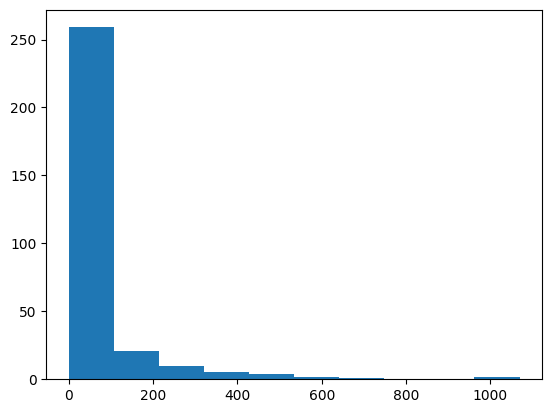

In [155]:
plt.hist(dementia['DaysSincePriorVisit'])

In [170]:
ed_counts.sort_values()

PatientDurableKey
247         1
6345992     1
6346256     1
6359440     1
6360659     1
6427491     1
6437161     1
6476083     1
6481799     1
6515720     1
6547343     1
6334290     1
6564405     1
6593410     1
6598620     1
6612943     1
6618028     1
6654593     1
6665067     1
6670594     1
6755739     1
6789355     1
6820674     1
6579613     1
6840762     1
6321998     1
6209721     1
5773116     1
10206443    1
5815955     1
5816610     1
5901030     1
5905830     1
5936505     1
5971317     1
6003295     1
6010824     1
6226612     1
6016508     1
6019606     1
6104557     1
6110981     1
6121641     1
6151502     1
6163013     1
6174688     1
6176425     1
6183112     1
6200364     1
6017360     1
6852918     1
6922402     1
7048081     1
8666089     1
8671650     1
8677276     1
8688091     1
8699361     1
8714465     1
8722577     1
8727832     1
8738631     1
8761776     1
8651792     1
8766868     1
8960802     1
9017365     1
9024460     1
9028874     1
9601133     1
96

In [186]:
dementia.loc[(dementia['PatientDurableKey'] == 407259)]['AdmissionSource']

122       Clinic or Physician's Office
123       Clinic or Physician's Office
124       Clinic or Physician's Office
4817      Clinic or Physician's Office
4854      Clinic or Physician's Office
4861      Clinic or Physician's Office
33795     Clinic or Physician's Office
95334     Clinic or Physician's Office
104750    Clinic or Physician's Office
108214    Clinic or Physician's Office
108244    Clinic or Physician's Office
108304    Clinic or Physician's Office
108310    Clinic or Physician's Office
161185       Clinic/Physician Referral
161620    Clinic or Physician's Office
210252    Clinic or Physician's Office
217000    Clinic or Physician's Office
221302    Clinic or Physician's Office
227474    Clinic or Physician's Office
230572    Clinic or Physician's Office
233024    Clinic or Physician's Office
233032    Clinic or Physician's Office
233035    Clinic or Physician's Office
258974    Clinic or Physician's Office
267871    Clinic or Physician's Office
303683       Clinic/Physi

In [185]:
ed_counts.sum()

np.int64(237)

In [178]:
dementia['AdmissionSource'].value_counts()

AdmissionSource
Clinic or Physician's Office                                                 482
Non-Health Care Facility Point of Origin                                     205
Clinic/Physician Referral                                                     19
Transfer from Skilled Nursing (SNF) or Intermediate Care Facility (ICF)       16
Transfer from Another Health Care Facility                                    10
Home                                                                           6
Transfer from a Hospital (Different Facility)                                  5
Transfer from One Distinct Unit to another Distinct Unit in Same Hospital      1
Name: count, dtype: int64

In [187]:
dementia.head()

,DiagnosisKey,GroupName,GroupCode,DiagnosisName,DiagnosisValue,dx_clean,Date,AdmissionInstant,AdmitYear,AdmitMonth,...,DischargeProviderDurableKey,DepartmentKey,PrimaryDiagnosisKey,IsEdVisit,IsHospitalAdmission,IsHospitalOutpatientVisit,IsInpatientAdmission,IsObservation,IsOutpatientFaceToFaceVisit,is_home_origin
122,857910.0,Alzheimer's disease,ICD-10-CM: G30,"Alzheimer's disease, unspecified (CMS-HCC)( IC...",G30.9,G30,01/13/22,2022-01-13 12:13:00,2022.0,1.0,...,1089,165,857910,0,0,0,0,0,1,False
123,857910.0,Alzheimer's disease,ICD-10-CM: G30,"Alzheimer's disease, unspecified (CMS-HCC)( IC...",G30.9,G30,02/10/22,2022-02-10 12:59:00,2022.0,2.0,...,1089,165,857910,0,0,0,0,0,1,False
124,857910.0,Alzheimer's disease,ICD-10-CM: G30,"Alzheimer's disease, unspecified (CMS-HCC)( IC...",G30.9,G30,03/10/22,2022-03-10 12:12:00,2022.0,3.0,...,1089,165,857910,0,0,0,0,0,1,False
2983,930167.0,Unspecified dementia,ICD-10-CM: F03,"Unspecified dementia, unspecified severity, wi...",F03.90,F03,01/03/22,2022-01-03 13:39:00,2022.0,1.0,...,-1,152,930167,0,0,1,0,0,1,False
3219,1302884.0,Alzheimer's disease,ICD-10-CM: G30,"Alzheimer's disease, unspecified (CMS-HCC)( IC...",G30.9,G30,03/07/22,2022-03-07 10:29:00,2022.0,3.0,...,1089,165,1302884,0,0,0,0,0,1,False


In [206]:
# 1. Convert both the admission and discharge columns to datetime
dementia['AdmissionInstant'] = pd.to_datetime(dementia['AdmissionInstant'], errors='coerce')
dementia['DischargeInstant'] = pd.to_datetime(dementia['DischargeInstant'], errors='coerce')

# 2. Sort and shift again to make sure the 'PrevDischarge' is now a datetime object
dementia = dementia.sort_values(['PatientDurableKey', 'AdmissionInstant'])
dementia['PrevDischarge'] = dementia.groupby('PatientDurableKey')['DischargeInstant'].shift(1)

# 3. Now the subtraction will work!
dementia['DaysBetweenVisits'] = (dementia['AdmissionInstant'] - dementia['PrevDischarge']).dt.days

# 4. Fill NaNs for the first visit
dementia['DaysBetweenVisits'] = dementia['DaysBetweenVisits'].fillna(-1)

In [207]:
def analyze_transition(row):
    if row['PrevIntensity'] == 3 and row['CareIntensity'] == 2: # Inpatient to ED
        if row['DaysBetweenVisits'] <= 0:
            return 'Internal Transfer'
        elif 1 <= row['DaysBetweenVisits'] <= 30:
            return 'Failed Discharge (Readmission)'
        else:
            return 'New Journey'
    return 'Other'

dementia['TransitionType'] = dementia.apply(analyze_transition, axis=1)

# See the breakdown
print(dementia[dementia['PrevIntensity'] == 3]['TransitionType'].value_counts())


TransitionType
New Journey    1
Name: count, dtype: int64


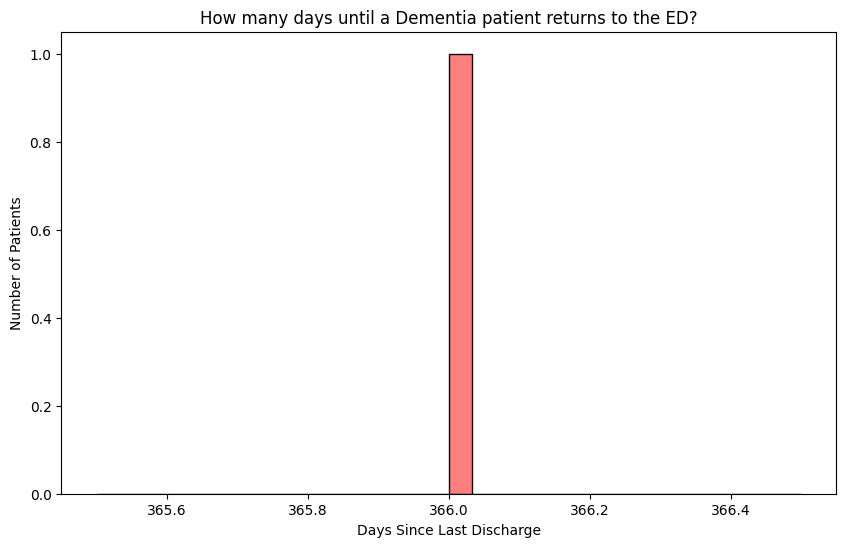

In [208]:


# Filter for only the people who returned after an Inpatient stay
returns = dementia[(dementia['PrevIntensity'] == 3) & (dementia['DaysBetweenVisits'] >= 0)]

plt.figure(figsize=(10, 6))
sns.histplot(returns['DaysBetweenVisits'], bins=30, kde=True, color='red')
plt.title('How many days until a Dementia patient returns to the ED?')
plt.xlabel('Days Since Last Discharge')
plt.ylabel('Number of Patients')
plt.show()

In [209]:
# Check the raw numbers
print("Distribution of gaps (in days):")
print(returns['DaysBetweenVisits'].value_counts())

# See the specific patients with a 1-day gap
short_gaps = returns[returns['DaysBetweenVisits'] <= 30]
print(f"Number of patients returning within 30 days: {len(short_gaps)}")

Distribution of gaps (in days):
DaysBetweenVisits
366.0    1
Name: count, dtype: int64
Number of patients returning within 30 days: 0


In [211]:
# 1. Look at the raw distribution of ALL gaps
print("Raw Gap Distribution:")
print(dementia['DaysBetweenVisits'].value_counts().sort_index().head(20))

# 2. Look specifically at the Inpatient -> ED transitions
escalations = dementia[(dementia['PrevIntensity'] == 3) & (dementia['CareIntensity'] == 2)]
print("\nInpatient to ED Gaps:")
print(escalations['DaysBetweenVisits'].value_counts().sort_index())

Raw Gap Distribution:
DaysBetweenVisits
-1.0     460
 0.0      17
 1.0       2
 2.0       7
 3.0       3
 4.0       3
 5.0       4
 6.0      18
 7.0       6
 8.0       2
 9.0       2
 10.0      4
 11.0      1
 12.0     10
 13.0      7
 14.0      1
 15.0      1
 16.0      2
 17.0      2
 18.0      1
Name: count, dtype: int64

Inpatient to ED Gaps:
DaysBetweenVisits
366.0    1
Name: count, dtype: int64


In [212]:
dementia['IsInpatientAdmission'].value_counts()

IsInpatientAdmission
0    639
1    105
Name: count, dtype: int64

In [213]:
# Look at transitions for EVERYONE, not just dementia patients
dementia = dementia.sort_values(['PatientDurableKey', 'AdmissionInstant'])
dementia['PrevIntensity'] = dementia.groupby('PatientDurableKey')['CareIntensity'].shift(1)

# Count transitions across the whole hospital
print("All Hospital Transitions:")
print(pd.crosstab(dementia['PrevIntensity'], dementia['CareIntensity']))

All Hospital Transitions:
CareIntensity    1   2  3
PrevIntensity            
1.0            274   3  5
2.0              2  14  5
3.0              0   1  0


/var/folders/qt/47k9y_w17z991s1knvcgn4fm0000gn/T/ipykernel_49874/2797896900.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Count', y='VisitType', data=visit_dist, palette='viridis')


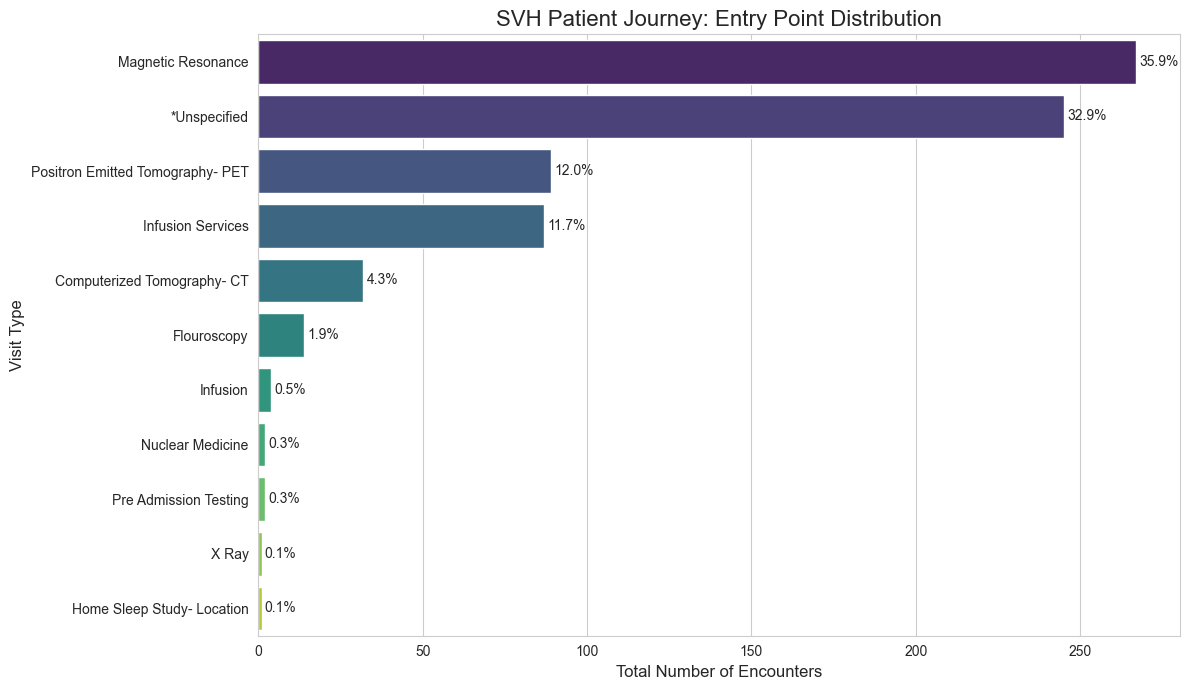

In [215]:


# 1. Group by Visit Type and count encounters
visit_dist = dementia['VisitTypeDescription'].value_counts().reset_index()
visit_dist.columns = ['VisitType', 'Count']

# 2. Calculate percentages for the 'Story'
visit_dist['Percentage'] = (visit_dist['Count'] / visit_dist['Count'].sum()) * 100

# 3. Create the Visualization
plt.figure(figsize=(12, 7))
sns.set_style("whitegrid")

# Create bar plot
ax = sns.barplot(x='Count', y='VisitType', data=visit_dist, palette='viridis')

# Add percentage labels to the bars
for i, p in enumerate(ax.patches):
    width = p.get_width()
    ax.text(width + 1, p.get_y() + p.get_height()/2, 
            f'{visit_dist["Percentage"].iloc[i]:.1f}%', 
            va='center')

plt.title('SVH Patient Journey: Entry Point Distribution', fontsize=16)
plt.xlabel('Total Number of Encounters', fontsize=12)
plt.ylabel('Visit Type', fontsize=12)
plt.tight_layout()
plt.show()

In [220]:
dementia['VisitTypeDescription'].value_counts()

VisitTypeDescription
Magnetic Resonance                  267
*Unspecified                        245
Positron Emitted Tomography- PET     89
Infusion Services                    87
Computerized Tomography- CT          32
Flouroscopy                          14
Infusion                              4
Nuclear Medicine                      2
Pre Admission Testing                 2
X Ray                                 1
Home Sleep Study- Location            1
Name: count, dtype: int64

/var/folders/qt/47k9y_w17z991s1knvcgn4fm0000gn/T/ipykernel_49874/3427117259.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Count', y='VisitType', data=visit_dist, palette='viridis')


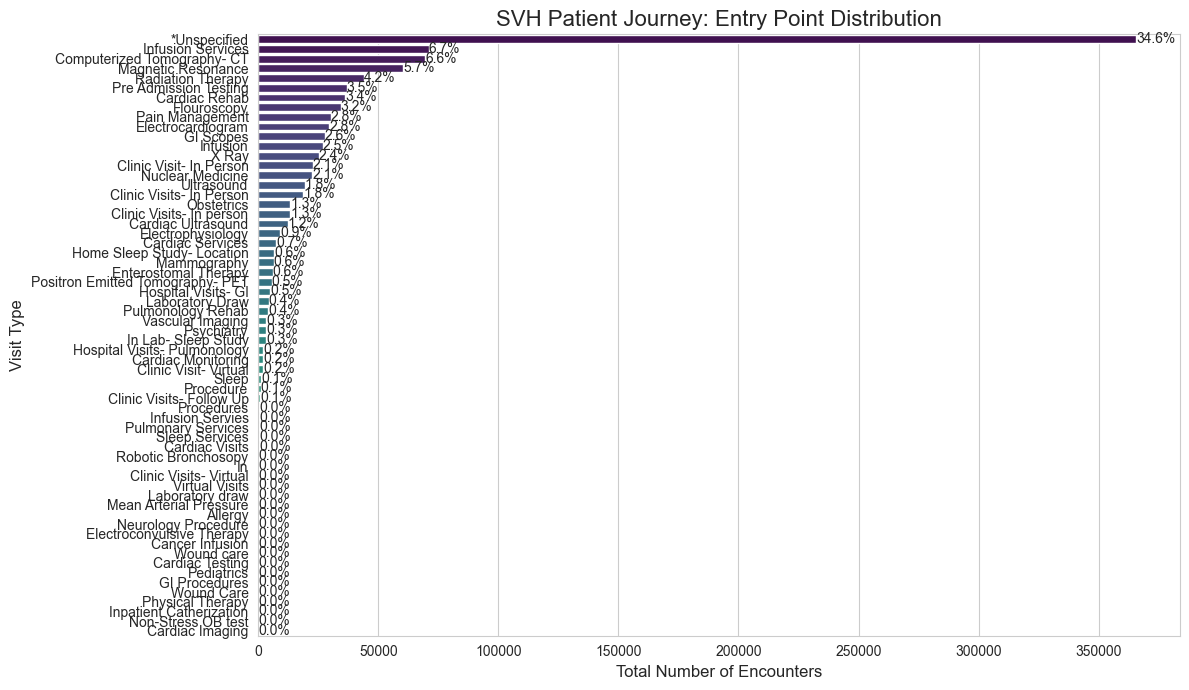

In [216]:
# 1. Group by Visit Type and count encounters
visit_dist = merge['VisitTypeDescription'].value_counts().reset_index()
visit_dist.columns = ['VisitType', 'Count']

# 2. Calculate percentages for the 'Story'
visit_dist['Percentage'] = (visit_dist['Count'] / visit_dist['Count'].sum()) * 100

# 3. Create the Visualization
plt.figure(figsize=(12, 7))
sns.set_style("whitegrid")

# Create bar plot
ax = sns.barplot(x='Count', y='VisitType', data=visit_dist, palette='viridis')

# Add percentage labels to the bars
for i, p in enumerate(ax.patches):
    width = p.get_width()
    ax.text(width + 1, p.get_y() + p.get_height()/2, 
            f'{visit_dist["Percentage"].iloc[i]:.1f}%', 
            va='center')

plt.title('SVH Patient Journey: Entry Point Distribution', fontsize=16)
plt.xlabel('Total Number of Encounters', fontsize=12)
plt.ylabel('Visit Type', fontsize=12)
plt.tight_layout()
plt.show()

In [225]:
merge.head()

,DiagnosisKey,GroupName,GroupCode,DiagnosisName,DiagnosisValue,Date,AdmissionInstant,AdmitYear,AdmitMonth,AdmitDay,...,DischargeProviderDurableKey,DepartmentKey,PrimaryDiagnosisKey,IsEdVisit,IsHospitalAdmission,IsHospitalOutpatientVisit,IsInpatientAdmission,IsObservation,IsOutpatientFaceToFaceVisit,is_home_origin
0,910699.0,Maternal care for other conditions predominant...,ICD-10-CM: O26,"Other specified pregnancy related conditions, ...",O26.893,04/25/22,2022-04-25 20:33:00,2022.0,4.0,25.0,...,2982,27,910699,0,1,0,0,1,0,False
1,NaN,NaN,NaN,NaN,NaN,04/29/22,2022-04-29 18:18:00,2022.0,4.0,29.0,...,2979,27,-1,0,1,0,0,1,0,False
2,468738.0,Maternal care for abnormality of pelvic organs,ICD-10-CM: O34,Maternal care for low transverse scar from pre...,O34.211,01/10/22,2022-01-10 05:52:00,2022.0,1.0,10.0,...,7015,27,468738,0,1,0,1,0,0,False
3,468492.0,Pre-eclampsia,ICD-10-CM: O14,"Mild to moderate pre-eclampsia, complicating c...",O14.04,03/08/22,2022-03-08 09:08:00,2022.0,3.0,8.0,...,7973,27,468492,0,1,0,1,0,0,False
4,907210.0,Supervision of high risk pregnancy,ICD-10-CM: O09,Supervision of pregnancy with insufficient ant...,O09.30,03/16/22,2022-03-16 14:19:00,2022.0,3.0,16.0,...,2982,27,907210,0,1,0,0,1,0,False


In [228]:
# 1. Clean the ICD-10 codes (taking the first 3 characters)
# We use .astype(str) to avoid errors if there are any NaNs
merge['dx_clean'] = merge['GroupCode'].astype(str).str.extract(r'([A-Z]\d{2})')

# 2. Define Chronic Illness Categories
chronic_map = {
    'E11': 'Diabetes Type 2',
    'E10': 'Diabetes Type 1',
    'I10': 'Hypertension',
    'I25': 'Chronic Ischemic Heart Disease',
    'J44': 'COPD',
    'J45': 'Asthma',
    'N18': 'Chronic Kidney Disease',
    'C00': 'Cancer (Malignant Neoplasms)', # This covers the C-range start
    'F32': 'Depression',
    'G30': 'Alzheimers'
}

# 3. Create the Chronic Label
merge['Chronic_Condition'] = merge['dx_clean'].map(chronic_map)

# 4. Filter for only chronic patients
chronic_df = merge[merge['Chronic_Condition'].notna()].copy()

print(f"Found {len(chronic_df)} encounters related to specific chronic illnesses.")
def classify_chronic_broad(dx):
    if pd.isna(dx): return "Other"
    
    letter = dx[0]
    if letter == 'C': return 'Oncology'
    if letter == 'E': return 'Endocrine/Metabolic'
    if letter == 'G': return 'Neurological'
    if letter == 'I': return 'Circulatory/Heart'
    if letter == 'N': return 'Renal/Urinary'
    if letter == 'F': return 'Mental Health'
    if letter == 'S': return 'Acute Injury' # These are your fractures!
    return "Other"

merge['Broad_Category'] = merge['dx_clean'].apply(classify_chronic_broad)

# See the breakdown of your entire hospital's population
print(merge['Broad_Category'].value_counts())

Found 30632 encounters related to specific chronic illnesses.
Broad_Category
Other                  802274
Circulatory/Heart       64329
Acute Injury            52555
Renal/Urinary           33078
Oncology                33036
Neurological            28189
Mental Health           21537
Endocrine/Metabolic     21375
Name: count, dtype: int64


In [229]:
merge['Chronic_Condition'].value_counts()

Chronic_Condition
Chronic Ischemic Heart Disease    8739
Diabetes Type 2                   5800
Hypertension                      4522
Asthma                            4321
COPD                              3106
Chronic Kidney Disease            1395
Depression                        1297
Diabetes Type 1                   1218
Alzheimers                         228
Cancer (Malignant Neoplasms)         6
Name: count, dtype: int64

In [230]:
# 1. Ensure your diagnosis cleaning column is active
merge['dx_prefix'] = merge['GroupCode'].astype(str).str.extract(r'([A-Z]\d{2})')

# 2. Define your Chronic 'Red Flags'
# This list covers the big three: Diabetes (E), Heart (I), and Kidney (N)
chronic_codes = ['E10', 'E11', 'I10', 'I11', 'I25', 'N18', 'J44', 'J45']

# 3. Find the 'Unique Keys' of patients who have at least one of these codes
chronic_patient_ids = merge[merge['dx_prefix'].isin(chronic_codes)]['PatientDurableKey'].unique()

# 4. Filter the MAIN dataframe to keep EVERY visit for those specific people
chronic_journeys = merge[merge['PatientDurableKey'].isin(chronic_patient_ids)].copy()

print(f"Total Chronic Patients: {len(chronic_patient_ids)}")
print(f"Total Encounters in Chronic Journeys: {len(chronic_journeys)}")

Total Chronic Patients: 15592
Total Encounters in Chronic Journeys: 224958


In [231]:
# Check the top 10 visit types for your new chronic cohort
print(chronic_journeys['VisitTypeDescription'].value_counts().head(10))

VisitTypeDescription
*Unspecified                   64845
Cardiac Rehab                  26616
Infusion Services              18243
Computerized Tomography- CT    14459
Electrocardiogram              10553
Radiation Therapy               8968
Magnetic Resonance              8873
Pre Admission Testing           7843
Nuclear Medicine                6991
Infusion                        6354
Name: count, dtype: int64


/var/folders/qt/47k9y_w17z991s1knvcgn4fm0000gn/T/ipykernel_49874/1818145040.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Count', y='VisitType', data=visit_dist, palette='viridis')


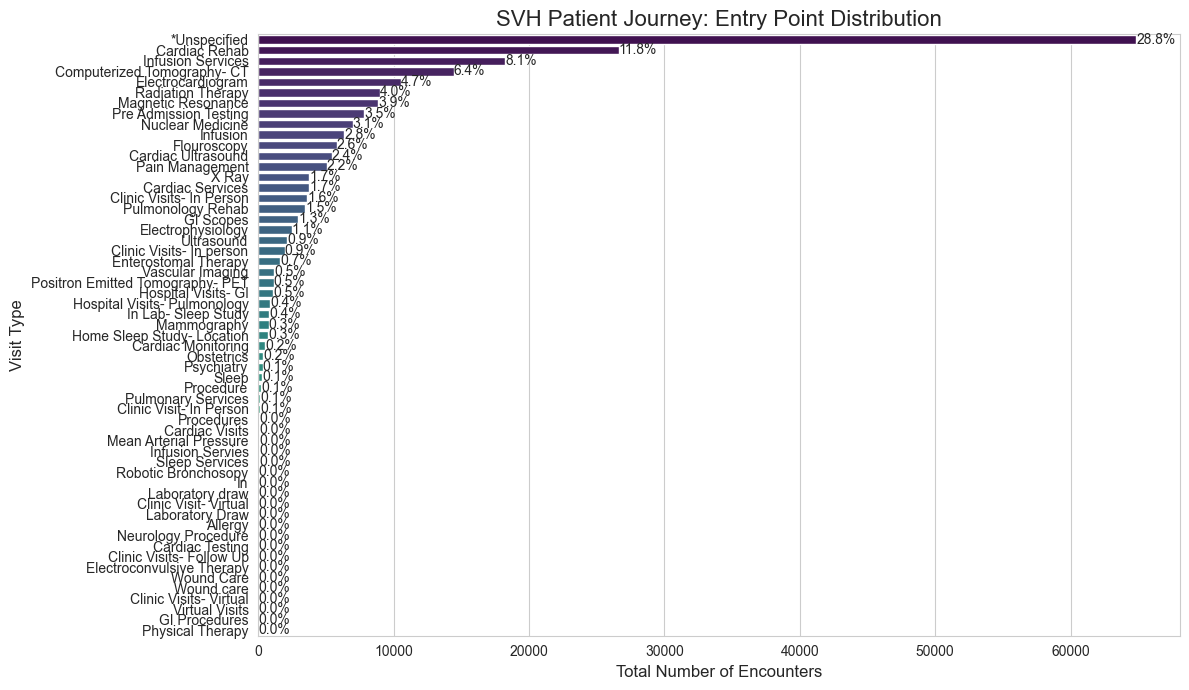

In [257]:
# 1. Group by Visit Type and count encounters
visit_dist =  chronic_journeys['VisitTypeDescription'].value_counts().reset_index()
visit_dist.columns = ['VisitType', 'Count']

# 2. Calculate percentages for the 'Story'
visit_dist['Percentage'] = (visit_dist['Count'] / visit_dist['Count'].sum()) * 100

# 3. Create the Visualization
plt.figure(figsize=(12, 7))
sns.set_style("whitegrid")

# Create bar plot
ax = sns.barplot(x='Count', y='VisitType', data=visit_dist, palette='viridis')

# Add percentage labels to the bars
for i, p in enumerate(ax.patches):
    width = p.get_width()
    ax.text(width + 1, p.get_y() + p.get_height()/2, 
            f'{visit_dist["Percentage"].iloc[i]:.1f}%', 
            va='center')

plt.title('SVH Patient Journey: Entry Point Distribution', fontsize=16)
plt.xlabel('Total Number of Encounters', fontsize=12)
plt.ylabel('Visit Type', fontsize=12)
plt.tight_layout()
plt.show()

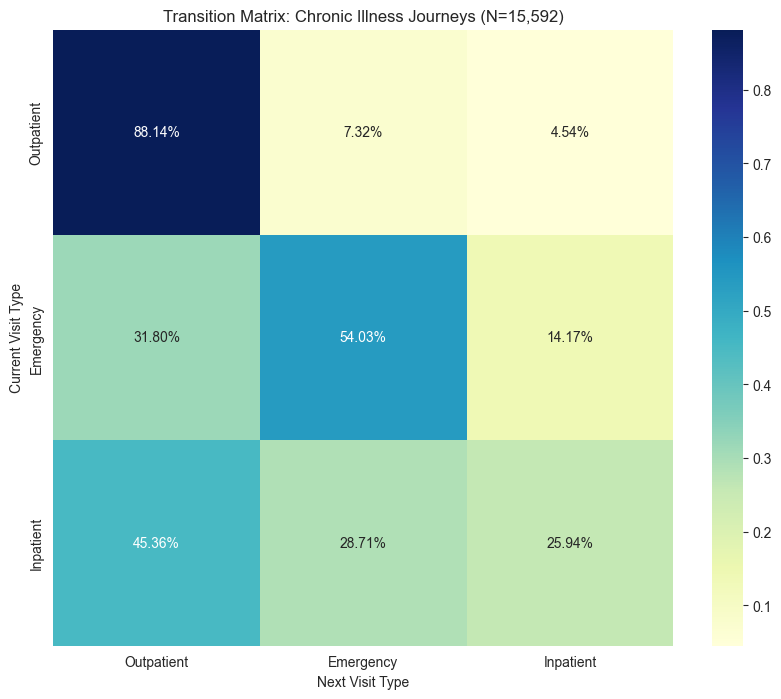

In [256]:
# Re-run intensity mapping on the new cohort
def get_intensity(row):
    if row['IsInpatientAdmission']: return 3
    elif row['IsEdVisit']: return 2
    elif row['IsOutpatientFaceToFaceVisit']: return 1
    else: return 0

chronic_journeys['CareIntensity'] = chronic_journeys.apply(get_intensity, axis=1)
chronic_journeys = chronic_journeys.sort_values(['PatientDurableKey', 'AdmissionInstant'])
chronic_journeys['PrevIntensity'] = chronic_journeys.groupby('PatientDurableKey')['CareIntensity'].shift(1)

# Generate the Heatmap
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Filter out the 0 (Other) categories for a cleaner clinical story
clean_matrix = chronic_journeys[(chronic_journeys['PrevIntensity'] > 0) & (chronic_journeys['CareIntensity'] > 0)]
matrix = pd.crosstab(clean_matrix['PrevIntensity'], clean_matrix['CareIntensity'], normalize='index')

# Plot
plt.figure(figsize=(10, 8))
sns.heatmap(matrix, xticklabels=['Outpatient', 'Emergency', 'Inpatient'], yticklabels= ['Outpatient', 'Emergency', 'Inpatient'], annot=True, fmt='.2%', cmap='YlGnBu')
plt.title('Transition Matrix: Chronic Illness Journeys (N=15,592)')
plt.xlabel('Next Visit Type')
plt.ylabel('Current Visit Type')
labels = ['Outpatient', 'Emergency', 'Inpatient']
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels)
ax.set_yticklabels(labels)
plt.show()

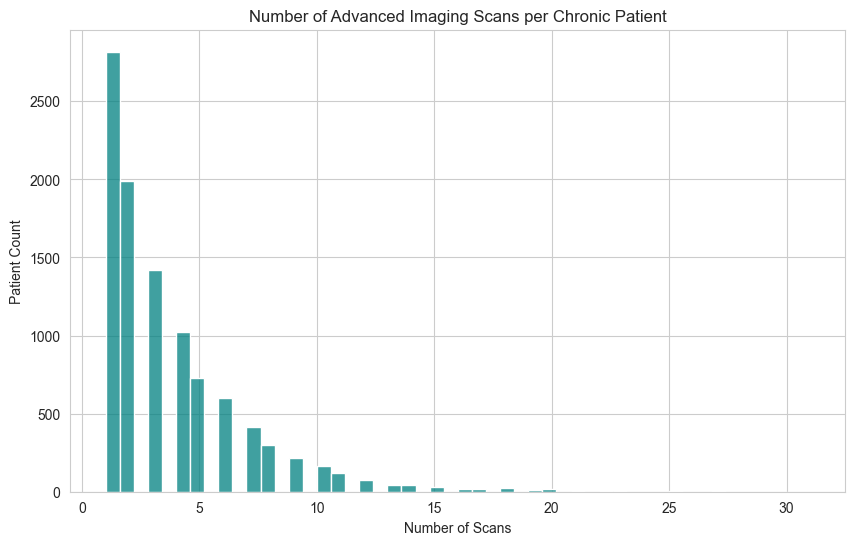

In [233]:
# Count imaging per patient
imaging_counts = chronic_journeys[chronic_journeys['VisitTypeDescription'].str.contains('Resonance|CT|PET', na=False, case=False)]
imaging_per_patient = imaging_counts.groupby('PatientDurableKey').size()

# Show the distribution
plt.figure(figsize=(10,6))
sns.histplot(imaging_per_patient, bins=50, color='teal')
plt.title('Number of Advanced Imaging Scans per Chronic Patient')
plt.xlabel('Number of Scans')
plt.ylabel('Patient Count')
plt.show()

In [234]:
# 1. Get scan counts per patient
scan_counts = chronic_journeys[chronic_journeys['VisitTypeDescription'].str.contains('Resonance|CT|PET', na=False, case=False)].groupby('PatientDurableKey').size()

# 2. Get ED visit counts per patient
ed_counts = chronic_journeys[chronic_journeys['IsEdVisit'] == True].groupby('PatientDurableKey').size()

# 3. Merge and check correlation
correlation_df = pd.DataFrame({'scans': scan_counts, 'ed_visits': ed_counts}).fillna(0)
print(f"Correlation between number of scans and ED visits: {correlation_df.corr().iloc[0,1]:.2f}")

Correlation between number of scans and ED visits: 0.03


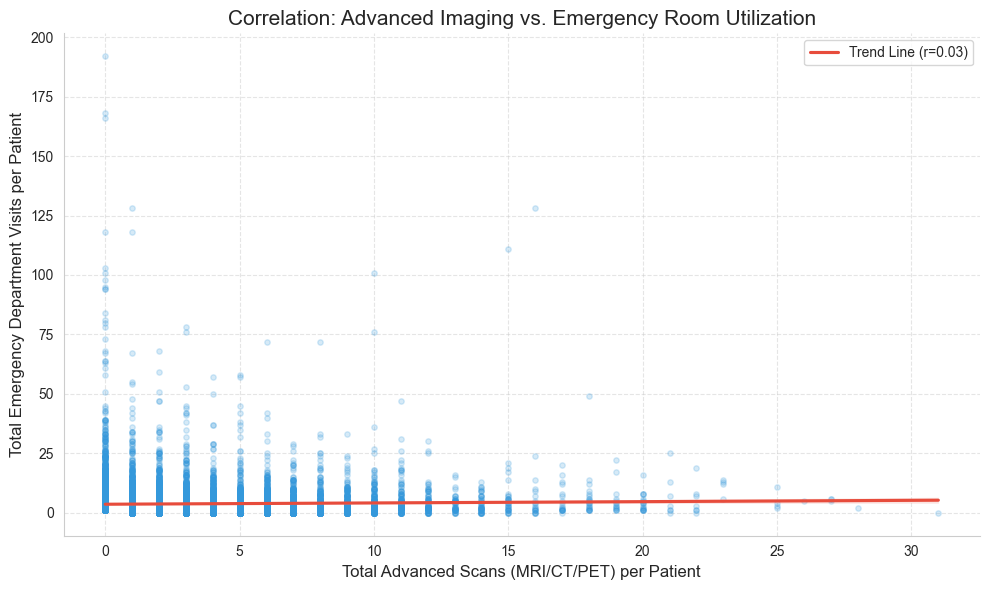

In [262]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Create the figure
plt.figure(figsize=(10, 6))

# 2. Use regplot to show the scatter points AND the trend line
# We use 'alpha' because with 15k patients, many points will overlap
sns.regplot(data=correlation_df, x='scans', y='ed_visits', 
            scatter_kws={'alpha':0.2, 's':15, 'color':'#3498db'}, 
            line_kws={'color':'#e74c3c', 'label':'Trend Line (r=0.03)'})

# 3. Add titles and labels
plt.title('Correlation: Advanced Imaging vs. Emergency Room Utilization', fontsize=15)
plt.xlabel('Total Advanced Scans (MRI/CT/PET) per Patient', fontsize=12)
plt.ylabel('Total Emergency Department Visits per Patient', fontsize=12)

# 4. Add a legend to highlight the near-zero correlation
plt.legend()

# 5. Clean up the look
plt.grid(True, linestyle='--', alpha=0.5)
sns.despine()

plt.tight_layout()
plt.savefig('imaging_vs_ed_correlation.png', dpi=300)

In [236]:
# 1. Ensure datetime conversion
chronic_journeys['AdmissionInstant'] = pd.to_datetime(chronic_journeys['AdmissionInstant'], errors='coerce')
chronic_journeys['DischargeInstant'] = pd.to_datetime(chronic_journeys['DischargeInstant'], errors='coerce')

# 2. Calculate Length of Stay (LOS) in hours
chronic_journeys['LOS_Hours'] = (chronic_journeys['DischargeInstant'] - chronic_journeys['AdmissionInstant']).dt.total_seconds() / 3600

# 3. Handle the 'Heavy Utilizer' mapping
# Use the correlation_df you just made to map scan counts back to the main chronic_journeys
chronic_journeys['Patient_Scan_Count'] = chronic_journeys['PatientDurableKey'].map(correlation_df['scans']).fillna(0)

# 4. Compare the groups
heavy_utilizers = chronic_journeys[chronic_journeys['Patient_Scan_Count'] > 10]
general_pop = chronic_journeys[chronic_journeys['Patient_Scan_Count'] <= 10]

print(f"Heavy Utilizer Avg LOS: {heavy_utilizers['LOS_Hours'].mean():.1f} hours")
print(f"General Population Avg LOS: {general_pop['LOS_Hours'].mean():.1f} hours")

Heavy Utilizer Avg LOS: 15.2 hours
General Population Avg LOS: 19.5 hours


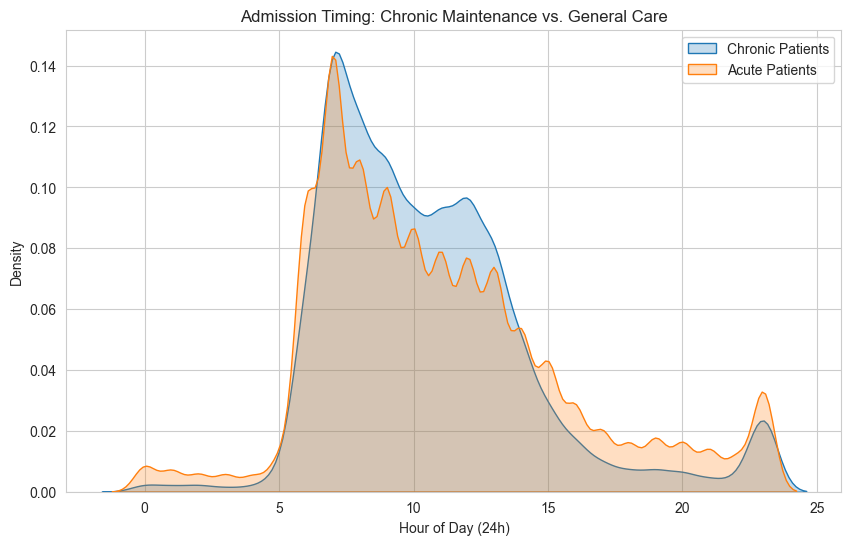

In [260]:
# Compare admission hour distribution
plt.figure(figsize=(10,6))
sns.kdeplot(heavy_utilizers['AdmitHour'], label='Chronic Patients', fill=True)
sns.kdeplot(general_pop['AdmitHour'], label='Acute Patients', fill=True)
plt.title('Admission Timing: Chronic Maintenance vs. General Care')
plt.xlabel('Hour of Day (24h)')
plt.legend()
plt.show()

In [239]:
# Check if Heavy Utilizers are actually 'admitted'
print("Heavy Utilizer Admission Status:")
print(heavy_utilizers['IsInpatientAdmission'].value_counts(normalize=True))

Heavy Utilizer Admission Status:
IsInpatientAdmission
0    0.955089
1    0.044911
Name: proportion, dtype: float64


In [244]:
# 1. Ensure time columns are datetime objects
chronic_journeys['AdmissionInstant'] = pd.to_datetime(chronic_journeys['AdmissionInstant'], errors='coerce')
chronic_journeys['DischargeInstant'] = pd.to_datetime(chronic_journeys['DischargeInstant'], errors='coerce')

# 2. Re-calculate the gap on the FULL sorted dataframe
chronic_journeys = chronic_journeys.sort_values(['PatientDurableKey', 'AdmissionInstant'])
chronic_journeys['PrevDischarge'] = chronic_journeys.groupby('PatientDurableKey')['DischargeInstant'].shift(1)
chronic_journeys['DaysBetweenVisits'] = (chronic_journeys['AdmissionInstant'] - chronic_journeys['PrevDischarge']).dt.days

# 3. Map your scan counts back to the main df
chronic_journeys['Patient_Scan_Count'] = chronic_journeys['PatientDurableKey'].map(correlation_df['scans']).fillna(0)

# 4. Now recreate your subsets
heavy_utilizers = chronic_journeys[chronic_journeys['Patient_Scan_Count'] > 10].copy()
general_pop = chronic_journeys[chronic_journeys['Patient_Scan_Count'] <= 10].copy()

# 5. Check the LOS and Gap
print(f"Heavy Utilizer Avg Days Between Visits: {heavy_utilizers['DaysBetweenVisits'].mean():.1f}")
print(f"General Pop Avg Days Between Visits: {general_pop['DaysBetweenVisits'].mean():.1f}")

Heavy Utilizer Avg Days Between Visits: 24.1
General Pop Avg Days Between Visits: 56.4


In [245]:
# To find the 'Speed of Escalation'
escalations = chronic_journeys[(chronic_journeys['PrevIntensity'] == 1) & (chronic_journeys['CareIntensity'] == 3)]
print("Average days for an Outpatient to hit the Hospital bed:")
print(escalations['DaysBetweenVisits'].mean())

Average days for an Outpatient to hit the Hospital bed:
85.24324729891957


In [247]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

# 1. Create the Target Variable: Readmitted within 30 days?
chronic_journeys['is_readmission'] = ((chronic_journeys['DaysBetweenVisits'] <= 30) & (chronic_journeys['DaysBetweenVisits'] >= 0)).astype(int)

# 2. Engineering Features for the Model
# We want to know things about their PREVIOUS visit to predict the NEXT one
features = chronic_journeys.groupby('PatientDurableKey').agg({
    'LOS_Hours': 'mean',
    'Patient_Scan_Count': 'max',
    'CareIntensity': 'last',      # Their most recent intensity level
    'AdmitHour': 'last',          # Did they arrive during the 7am-9am rush?
    'dx_clean': 'nunique'         # How many different conditions do they have?
}).fillna(0)

# 3. Add the target (did their LAST visit result in a readmission?)
target = chronic_journeys.groupby('PatientDurableKey')['is_readmission'].max()

# Merge into a final modeling set
ml_data = features.join(target)
X = ml_data.drop('is_readmission', axis=1)
y = ml_data['is_readmission']

In [ ]:
# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Evaluate
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))
print(f"Model AUC Score: {roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]):.2f}")

              precision    recall  f1-score   support

           0       0.74      0.68      0.71       825
           1       0.89      0.91      0.90      2294

    accuracy                           0.85      3119
   macro avg       0.81      0.80      0.81      3119
weighted avg       0.85      0.85      0.85      3119

Model AUC Score: 0.91


In [249]:

importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Top Predictors of Readmission:")
print(importances)

Top Predictors of Readmission:
dx_clean              0.423334
LOS_Hours             0.343786
AdmitHour             0.116319
Patient_Scan_Count    0.090223
CareIntensity         0.026337
dtype: float64


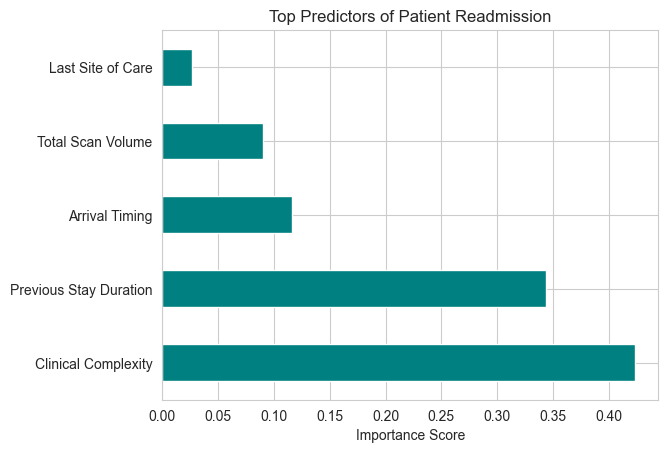

In [ ]:
# Create a dictionary to map your code names to "Boardroom" names
label_map = {
    'dx_clean': 'Clinical Complexity',
    'LOS_Hours': 'Previous Stay Duration',
    'AdmitHour': 'Arrival Timing',
    'Patient_Scan_Count': 'Total Scan Volume',
    'CareIntensity': 'Last Site of Care'
}

# Apply the map to your importance index
importances.index = importances.index.map(label_map)

# Plot
importances.plot(kind='barh', color='teal')
plt.title('Top Predictors of Patient Readmission')
plt.xlabel('Importance Score')
plt.show()

In [259]:
merge.head()

,DiagnosisKey,GroupName,GroupCode,DiagnosisName,DiagnosisValue,Date,AdmissionInstant,AdmitYear,AdmitMonth,AdmitDay,...,IsHospitalAdmission,IsHospitalOutpatientVisit,IsInpatientAdmission,IsObservation,IsOutpatientFaceToFaceVisit,is_home_origin,dx_clean,Chronic_Condition,Broad_Category,dx_prefix
0,910699.0,Maternal care for other conditions predominant...,ICD-10-CM: O26,"Other specified pregnancy related conditions, ...",O26.893,04/25/22,2022-04-25 20:33:00,2022.0,4.0,25.0,...,1,0,0,1,0,False,O26,NaN,Other,O26
1,NaN,NaN,NaN,NaN,NaN,04/29/22,2022-04-29 18:18:00,2022.0,4.0,29.0,...,1,0,0,1,0,False,NaN,NaN,Other,NaN
2,468738.0,Maternal care for abnormality of pelvic organs,ICD-10-CM: O34,Maternal care for low transverse scar from pre...,O34.211,01/10/22,2022-01-10 05:52:00,2022.0,1.0,10.0,...,1,0,1,0,0,False,O34,NaN,Other,O34
3,468492.0,Pre-eclampsia,ICD-10-CM: O14,"Mild to moderate pre-eclampsia, complicating c...",O14.04,03/08/22,2022-03-08 09:08:00,2022.0,3.0,8.0,...,1,0,1,0,0,False,O14,NaN,Other,O14
4,907210.0,Supervision of high risk pregnancy,ICD-10-CM: O09,Supervision of pregnancy with insufficient ant...,O09.30,03/16/22,2022-03-16 14:19:00,2022.0,3.0,16.0,...,1,0,0,1,0,False,O09,NaN,Other,O09
